# Practice: estimating Q and R in data assimilation (correction)

Translated from the [CEDA Buenos Aires 2019 correction notebook](https://github.com/ptandeo/CEDA/blob/master/tmp/CEDA_buenos_aires_2019_correction.ipynb). The original exercise uses `pykalman` for a scalar linear-Gaussian model and CEDA for Lorenz-63. Here the scalar Kalman filter/RTS smoother is implemented locally for teaching, and covariance EM and ensemble smoothing use `AnalogDataAssimilation.jl`.

The notebook uses `Plots`, available in the repository's `docs` environment. Start Jupyter with the repository's documentation environment (or activate `docs/Project.toml` in the Julia kernel). Set `CEDA_QUICK_DEMO=true` to shorten only the Lorenz-63 experiment; otherwise its 1,000 steps, 100 ensemble members, and 100 EM iterations match the source notebook.

## Problem statement and batch EM

Data assimilation combines observations `y` with a dynamical model `M` to estimate a hidden state `x`. In a state-space model, `xₖ = M(xₖ₋₁) + ηₖ` and `yₖ = H(xₖ) + εₖ`, where the independent, unbiased Gaussian model and observation errors have covariances `Q` and `R`.

Batch expectation-maximization alternates an E-step, estimating the hidden trajectory conditioned on all observations with a smoother, and an M-step, updating the unknown parameters. The scalar exercise uses the linear-Gaussian EM setting described by Shumway and Stoffer (1982); the Lorenz-63 exercise uses the package's ensemble Kalman smoother EM implementation.

In [1]:
import Pkg
Pkg.activate(joinpath(pwd(), "docs"))

using AnalogDataAssimilation
using LinearAlgebra
using Plots
using Random
using Statistics

const QUICK_DEMO = get(ENV, "CEDA_QUICK_DEMO", "false") == "true"

  Activating project at `~/Codes/copilot-worktrees/AnalogDataAssimilation.jl/pnavaro-jubilant-broccoli/docs`
[ Info: Precompiling ProgressMeterIJuliaExt [e9b107ab-0deb-577e-b773-d2f164185625]
Precompiling packages...
   0.4 s  ✓ ProgressMeterIJuliaExt (serial)
  1 dependency successfully precompiled in 1 seconds
[ Info: Precompiling IJuliaExt [388d8a6b-6fe4-50b5-a981-2e7a5d676f34] (caches not reused: 1 for different dependency version already loaded, 1 for different Julia build configuration)
Precompiling packages...
   0.5 s  ✓ IJuliaExt (serial)
  1 dependency successfully precompiled in 1 seconds
[ Info: Precompiling IJuliaExt [6e0e26ac-fb43-584e-b323-fdbabcf95812] (caches not reused: 2 for different dependency version already loaded, 1 for different Julia build configuration)
Precompiling packages...
   1.0 s  ✓ IJuliaExt (serial)
  1 dependency successfully precompiled in 1 seconds


false

## Linear and Gaussian example

Generate 100 states from `xₖ = 0.95xₖ₋₁ + ηₖ` and observations `yₖ = xₖ + εₖ`, with true `Q = R = 1`. The source notebook initializes the first state from zero, which is used here as the state immediately before the first observation.

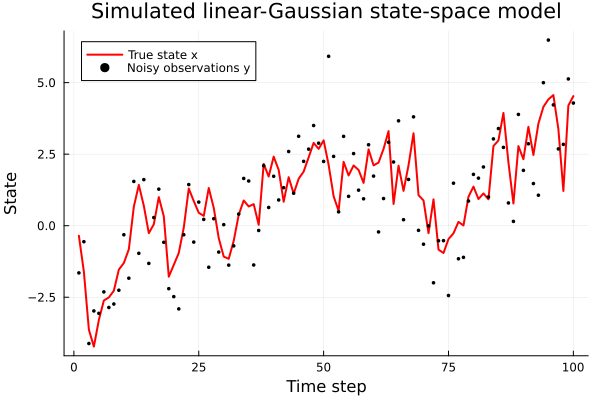

In [2]:
rng_linear = MersenneTwister(5)
const A_LINEAR = 0.95
const Q_LINEAR_TRUE = 1.0
const R_LINEAR_TRUE = 1.0
K_linear = 100

x_linear = zeros(K_linear)
y_linear = zeros(K_linear)
for k in 1:K_linear
    previous_state = k == 1 ? 0.0 : x_linear[k - 1]
    x_linear[k] = A_LINEAR * previous_state + sqrt(Q_LINEAR_TRUE) * randn(rng_linear)
    y_linear[k] = x_linear[k] + sqrt(R_LINEAR_TRUE) * randn(rng_linear)
end

plot(1:K_linear, x_linear; label = "True state x", color = :red, linewidth = 2,
     xlabel = "Time step", ylabel = "State",
     title = "Simulated linear-Gaussian state-space model")
scatter!(1:K_linear, y_linear; label = "Noisy observations y", color = :black, markersize = 2)

### Kalman filter and RTS smoother

The following scalar implementation returns smoothed means and variances. It provides the baseline comparison that `pykalman.KalmanFilter.smooth` produced in the Python notebook. First use the correct covariances, then compare with the deliberately poor guesses `Q = 0.5` and `R = 5`.

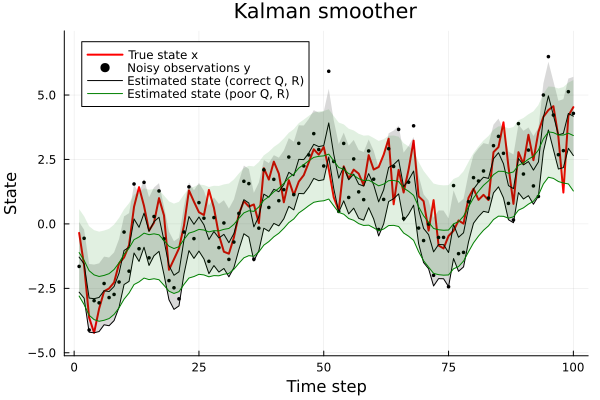

In [3]:
function scalar_kalman_smoother(y; transition, Q, R, initial_mean = 0.0, initial_variance = 1.0)
    n = length(y)
    filtered_mean = zeros(n + 1)
    filtered_variance = zeros(n + 1)
    forecast_mean = zeros(n)
    forecast_variance = zeros(n)
    filtered_mean[1] = initial_mean
    filtered_variance[1] = initial_variance

    for k in 1:n
        forecast_mean[k] = transition * filtered_mean[k]
        forecast_variance[k] = transition^2 * filtered_variance[k] + Q
        gain = forecast_variance[k] / (forecast_variance[k] + R)
        filtered_mean[k + 1] = forecast_mean[k] + gain * (y[k] - forecast_mean[k])
        filtered_variance[k + 1] = (1 - gain) * forecast_variance[k]
    end

    smoothed_mean = copy(filtered_mean)
    smoothed_variance = copy(filtered_variance)
    for k in n:-1:1
        gain = filtered_variance[k] * transition / forecast_variance[k]
        smoothed_mean[k] = filtered_mean[k] + gain * (smoothed_mean[k + 1] - forecast_mean[k])
        smoothed_variance[k] = filtered_variance[k] + gain^2 *
                               (smoothed_variance[k + 1] - forecast_variance[k])
    end
    return smoothed_mean[2:end], smoothed_variance[2:end]
end

smooth_good, variance_good = scalar_kalman_smoother(
    y_linear; transition = A_LINEAR, Q = Q_LINEAR_TRUE, R = R_LINEAR_TRUE,
)
smooth_poor, variance_poor = scalar_kalman_smoother(
    y_linear; transition = A_LINEAR, Q = 0.5Q_LINEAR_TRUE, R = 5R_LINEAR_TRUE,
)

p_linear = plot(1:K_linear, x_linear; label = "True state x", color = :red, linewidth = 2,
                xlabel = "Time step", ylabel = "State", title = "Kalman smoother")
scatter!(p_linear, 1:K_linear, y_linear; label = "Noisy observations y", color = :black, markersize = 2)
plot!(p_linear, 1:K_linear, smooth_good; label = "Estimated state (correct Q, R)", color = :black)
plot!(p_linear, 1:K_linear, smooth_good .- 1.96 .* sqrt.(variance_good);
      label = nothing, fillrange = smooth_good .+ 1.96 .* sqrt.(variance_good), fillalpha = 0.15, color = :black)
plot!(p_linear, 1:K_linear, smooth_poor; label = "Estimated state (poor Q, R)", color = :green)
plot!(p_linear, 1:K_linear, smooth_poor .- 1.96 .* sqrt.(variance_poor);
      label = nothing, fillrange = smooth_poor .+ 1.96 .* sqrt.(variance_poor), fillalpha = 0.12, color = :green)
ylims!(p_linear, (minimum(y_linear) - 1, maximum(y_linear) + 1))
p_linear

### Estimate Q and R with EM

Start from the poor covariance guesses and estimate only `Q` and `R` for 100 iterations, keeping the initial state distribution fixed. In this linear case, the package's extended Kalman smoother is the exact Kalman smoother.

In [4]:
linear_observations = reshape(y_linear, 1, :)
linear_transition(x) = [A_LINEAR * x[1]]
linear_transition_jacobian(x) = reshape([A_LINEAR], 1, 1)
linear_observation_jacobian(x) = ones(1, 1)

linear_em = em_eks(
    linear_observations;
    initial_state = [0.0],
    initial_covariance = ones(1, 1),
    model_noise_covariance = reshape([0.5Q_LINEAR_TRUE], 1, 1),
    observation_noise_covariance = reshape([5R_LINEAR_TRUE], 1, 1),
    dynamics = linear_transition,
    dynamics_jacobian = linear_transition_jacobian,
    observation_jacobian = linear_observation_jacobian,
    iterations = 100,
    estimate_background = false,
)

println("Q estimates: ", linear_em.model_noise_covariance[1, 1, end])
println("R estimates: ", linear_em.observation_noise_covariance[1, 1, end])

Q estimates: 0.4142100044725268
R estimates: 1.3986488854032024


### Estimate the initial distribution as well

Repeat the scalar experiment with 1,000 observations. This time EM estimates the initial mean and covariance in addition to `Q` and `R`, corresponding to the four parameter groups selected in the source notebook.

In [5]:
K_linear_long = 1000
x_linear_long = zeros(K_linear_long)
y_linear_long = zeros(K_linear_long)
for k in 1:K_linear_long
    previous_state = k == 1 ? 0.0 : x_linear_long[k - 1]
    x_linear_long[k] = A_LINEAR * previous_state + sqrt(Q_LINEAR_TRUE) * randn(rng_linear)
    y_linear_long[k] = x_linear_long[k] + sqrt(R_LINEAR_TRUE) * randn(rng_linear)
end

linear_long_em = em_eks(
    reshape(y_linear_long, 1, :);
    initial_state = [0.0],
    initial_covariance = ones(1, 1),
    model_noise_covariance = reshape([0.5Q_LINEAR_TRUE], 1, 1),
    observation_noise_covariance = reshape([5R_LINEAR_TRUE], 1, 1),
    dynamics = linear_transition,
    dynamics_jacobian = linear_transition_jacobian,
    observation_jacobian = linear_observation_jacobian,
    iterations = 100,
)

println("Initial-state mean estimate: ", linear_long_em.background_state[1, end])
println("Initial-state variance estimate: ", linear_long_em.background_covariance[1, 1, end])
println("Q estimate: ", linear_long_em.model_noise_covariance[1, 1, end])
println("R estimate: ", linear_long_em.observation_noise_covariance[1, 1, end])

Initial-state mean estimate: 1.8101787513087546
Initial-state variance estimate: 0.017907275795703288
Q estimate: 1.056264292210096
R estimate: 0.9383249703764848


## Lorenz-63 example

The nonlinear experiment follows CEDA's setup: Lorenz-63 with `dt = 0.01`, `Q = 0.05I`, `R = 2I`, and observations every five model steps. It first compares EnKS state estimates with correct and deliberately poor observation-error covariance (`100R`), then estimates `Q` and `R` with EM-EnKS. The random-number seeds, initial state, and full-size run settings follow the source notebook.

In [6]:
function rk4_step(f, x, dt)
    k1 = f(x)
    k2 = f(x .+ (dt / 2) .* k1)
    k3 = f(x .+ (dt / 2) .* k2)
    k4 = f(x .+ dt .* k3)
    return x .+ (dt / 6) .* (k1 .+ 2 .* k2 .+ 2 .* k3 .+ k4)
end

const DT_L63 = 0.01
const SIGMA_L63, RHO_L63, BETA_L63 = 10.0, 28.0, 8 / 3
function lorenz63_rhs(x)
    [SIGMA_L63 * (x[2] - x[1]),
     x[1] * (RHO_L63 - x[3]) - x[2],
     x[1] * x[2] - BETA_L63 * x[3]]
end
lorenz63_transition(x) = rk4_step(lorenz63_rhs, x, DT_L63)

K_l63 = QUICK_DEMO ? 100 : 1000
N_ENSEMBLE = QUICK_DEMO ? 32 : 100
N_EM_ITER = QUICK_DEMO ? 5 : 100
Q_l63_true = 0.05 .* Matrix{Float64}(I, 3, 3)
R_l63_true = 2.0 .* Matrix{Float64}(I, 3, 3)
H_l63 = Matrix{Float64}(I, 3, 3)
initial_l63 = [6.39435776, 9.23172442, 19.15323224]

truth_l63 = zeros(3, K_l63 + 1)
truth_l63[:, 1] .= initial_l63
Q_factor_l63 = cholesky(Symmetric(Q_l63_true)).L
rng_l63_truth = MersenneTwister(5)
for k in 1:K_l63
    truth_l63[:, k + 1] .= lorenz63_transition(@view truth_l63[:, k]) +
                           Q_factor_l63 * randn(rng_l63_truth, 3)
end

observations_l63 = fill(NaN, 3, K_l63)
R_factor_l63 = cholesky(Symmetric(R_l63_true)).L
rng_l63_observations = MersenneTwister(5)
for k in 1:5:K_l63
    observations_l63[:, k] .= truth_l63[:, k + 1] +
                              R_factor_l63 * randn(rng_l63_observations, 3)
end

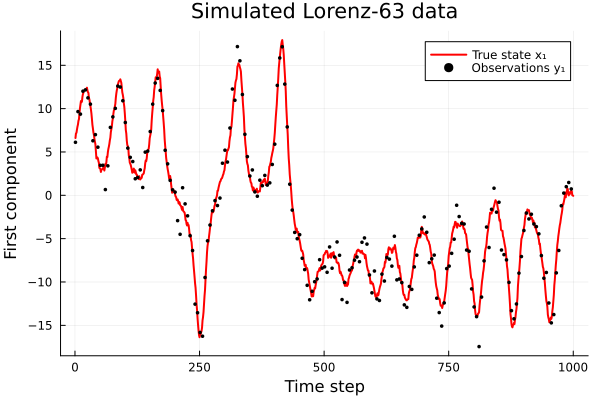

In [7]:
plot(1:K_l63, truth_l63[1, 2:end]; label = "True state x₁", color = :red, linewidth = 2,
     xlabel = "Time step", ylabel = "First component",
     title = "Simulated Lorenz-63 data")
scatter!(1:K_l63, observations_l63[1, :]; label = "Observations y₁", color = :black, markersize = 2)

### EnKS state estimates with good and poor R

Use one fixed-parameter EM smoother pass to obtain the EnKS trajectory and ensemble covariance, without updating the supplied parameters. The package result exposes the smoothed covariance at each time, so the plotted bands are ensemble-based 95% intervals.

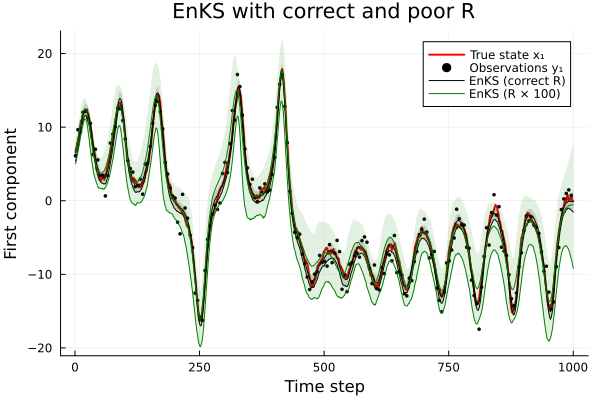

In [8]:
enks_options = (
    initial_state = initial_l63,
    initial_covariance = Matrix{Float64}(I, 3, 3),
    model_noise_covariance = Q_l63_true,
    dynamics = lorenz63_transition,
    observation_matrix = H_l63,
    ensemble_size = N_ENSEMBLE,
    iterations = 1,
    estimate_model_noise = false,
    estimate_observation_noise = false,
    estimate_background = false,
    truth = truth_l63,
)

enks_good = em_enks(
    observations_l63;
    enks_options...,
    observation_noise_covariance = R_l63_true,
    rng = MersenneTwister(5),
)
enks_poor = em_enks(
    observations_l63;
    enks_options...,
    observation_noise_covariance = 100 .* R_l63_true,
    rng = MersenneTwister(5),
)

good_mean = enks_good.smoothed_states[1, 2:end, 1]
good_std = sqrt.(enks_good.smoothed_covariances[1, 1, 2:end, 1])
poor_mean = enks_poor.smoothed_states[1, 2:end, 1]
poor_std = sqrt.(enks_poor.smoothed_covariances[1, 1, 2:end, 1])
p_enks = plot(1:K_l63, truth_l63[1, 2:end]; label = "True state x₁", color = :red, linewidth = 2,
              xlabel = "Time step", ylabel = "First component", title = "EnKS with correct and poor R")
scatter!(p_enks, 1:K_l63, observations_l63[1, :]; label = "Observations y₁", color = :black, markersize = 2)
plot!(p_enks, 1:K_l63, good_mean; label = "EnKS (correct R)", color = :black)
plot!(p_enks, 1:K_l63, good_mean .- 1.96 .* good_std;
      label = nothing, fillrange = good_mean .+ 1.96 .* good_std, fillalpha = 0.15, color = :black)
plot!(p_enks, 1:K_l63, poor_mean; label = "EnKS (R × 100)", color = :green)
plot!(p_enks, 1:K_l63, poor_mean .- 1.96 .* poor_std;
      label = nothing, fillrange = poor_mean .+ 1.96 .* poor_std, fillalpha = 0.12, color = :green)
p_enks

### Estimate Q and R with EM-EnKS

Initialize `Q` and `R` with identity matrices and initialize the background distribution from the simulated trajectory, as in CEDA. The diagnostics compare normalized covariance traces with their true values, alongside the observed-data log-likelihood and smoothed-state RMSE.

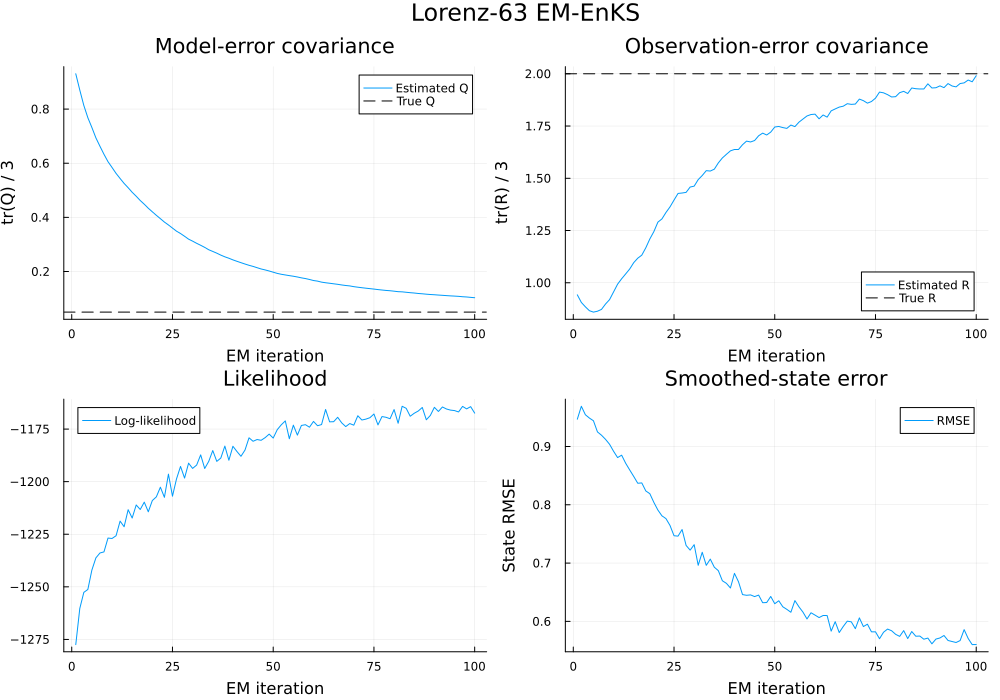

In [9]:
background_l63 = vec(mean(truth_l63, dims = 2))
centered_l63 = truth_l63 .- background_l63
background_covariance_l63 = centered_l63 * centered_l63' / (size(truth_l63, 2) - 1)

em_l63 = em_enks(
    observations_l63;
    initial_state = background_l63,
    initial_covariance = background_covariance_l63,
    model_noise_covariance = Matrix{Float64}(I, 3, 3),
    observation_noise_covariance = Matrix{Float64}(I, 3, 3),
    dynamics = lorenz63_transition,
    observation_matrix = H_l63,
    ensemble_size = N_ENSEMBLE,
    iterations = N_EM_ITER,
    truth = truth_l63,
    rng = MersenneTwister(5),
)

em_steps = 1:N_EM_ITER
pQ = plot(em_steps, [tr(em_l63.model_noise_covariance[:, :, i + 1]) / 3 for i in em_steps];
          label = "Estimated Q", xlabel = "EM iteration", ylabel = "tr(Q) / 3", title = "Model-error covariance")
hline!(pQ, [tr(Q_l63_true) / 3]; label = "True Q", color = :black, linestyle = :dash)
pR = plot(em_steps, [tr(em_l63.observation_noise_covariance[:, :, i + 1]) / 3 for i in em_steps];
          label = "Estimated R", xlabel = "EM iteration", ylabel = "tr(R) / 3", title = "Observation-error covariance")
hline!(pR, [tr(R_l63_true) / 3]; label = "True R", color = :black, linestyle = :dash)
pL = plot(em_steps, em_l63.loglikelihood; label = "Log-likelihood", xlabel = "EM iteration", title = "Likelihood")
pE = plot(em_steps, em_l63.rmse; label = "RMSE", xlabel = "EM iteration", ylabel = "State RMSE", title = "Smoothed-state error")
plot(pQ, pR, pL, pE; layout = (2, 2), size = (1000, 700), plot_title = "Lorenz-63 EM-EnKS")

The original exercise invites experimentation with the observation cadence and sequence length. In this translation, change the stride `1:5:K_l63` when generating `observations_l63`, or adjust `K_l63`, and rerun the Lorenz-63 cells. The scalar Kalman and EM exercises are included in full; the package does not add a separate general-purpose linear Kalman API for this notebook.